### Top Rows

In [102]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

file_path = "results-filtered-dataset.csv"
df = pd.read_csv(file_path)


In [ ]:
from IPython.display import display, Markdown
import numpy as np
import pandas as pd

group1 = 'v0'
group2 = 'v5'
branchings = 'S R P'

group1_alg = [f"{group1}-{br}" for br in branchings.split()]
group2_alg = [f"{group2}-{br}" for br in branchings.split()]

all_algos = group1_alg + group2_alg

# Ensure only existing columns are used
valid_cols = [c for c in all_algos if c in df.columns]

df[valid_cols] = (
    df[valid_cols]
    .replace("x", 1800)
    .apply(pd.to_numeric, errors="coerce")
)

df[f"{group1}_min"] = df[group1_alg].min(axis=1)
df[f"{group2}_min"] = df[group2_alg].min(axis=1)

# avoid divide-by-zero
df["ratio"] = (
    np.maximum(df[f"{group1}_min"], df[f"{group2}_min"])
    / np.maximum(np.minimum(df[f"{group1}_min"], df[f"{group2}_min"]), 1e-9)
)

filtered_rows = df[
    (df[f"{group1}_min"] > 1) &
    (df[f"{group2}_min"] > 1) &
    (df["ratio"] >= 2)
].sort_values(by="ratio", ascending=False).copy()

# Split into two tables
group1_wins_table = filtered_rows[
    filtered_rows[f"{group1}_min"] < filtered_rows[f"{group2}_min"]
]

group2_wins_table = filtered_rows[
    filtered_rows[f"{group2}_min"] < filtered_rows[f"{group1}_min"]
]

total = len(filtered_rows)

display(Markdown(f"""
## Experiment Summary
### Filtered rows: **{total}**
- {group1} faster: **{len(group1_wins_table)}**
- {group2} faster: **{len(group2_wins_table)}**
"""))

display(Markdown(f"## {group1} Wins"))
display(group1_wins_table[["dataset", "k", f"{group1}_min", f"{group2}_min", "ratio"]])

display(Markdown(f"## {group2} Wins"))
display(group2_wins_table[["dataset", "k", f"{group1}_min", f"{group2}_min", "ratio"]])

ratio_thresholds = [2, 4, 6, 8, 10]

group1_wins_list = []
group2_wins_list = []

den = np.minimum(df[f"{group1}_min"], df[f"{group2}_min"])
df["ratio"] = np.maximum(df[f"{group1}_min"], df[f"{group2}_min"]) / den.replace(0, np.nan)

for r in ratio_thresholds:
    filtered_rows = df[
        (df[f"{group1}_min"] > 1) &
        (df[f"{group2}_min"] > 1) &
        (df["ratio"] >= r)
    ]

    total = len(filtered_rows)

    group1_wins = (filtered_rows[f"{group1}_min"] < filtered_rows[f"{group2}_min"]).sum()
    group2_wins = total - group1_wins

    group1_wins_list.append(group1_wins)
    group2_wins_list.append(group2_wins)

# Plot
x = np.arange(len(ratio_thresholds))
width = 0.35

plt.figure()

plt.bar(x - width/2, group1_wins_list, width, label=f"{group1} wins")
plt.bar(x + width/2, group2_wins_list, width, label=f"{group2} wins")

plt.xticks(x, [f"{r}" for r in ratio_thresholds])
plt.xlabel("Ratio Threshold")
plt.ylabel("Number of Wins")
plt.title(f"{group1} vs {group2} Wins by Ratio Threshold")

plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.show()


## Experiment Summary
### Filtered rows: **150**
- v4 faster: **80**
- v5 faster: **70**


## v4 Wins

,dataset,k,v4_min,v5_min,ratio
4019,TSOPF_RS_b2383_c1,4,25.2535,1800.0000,71.277249
533,bmwcra_1,10,28.4871,1800.0000,63.186495
4013,TSOPF_RS_b2383,4,34.3479,1800.0000,52.404951
1954,link-dynamic-frwiki,20,8.0969,328.7408,40.600823
4008,TSOPF_RS_b2052_c1,6,9.4756,218.8099,23.091931
...,...,...,...,...,...
1741,ia-wiki-Talk-dir,8,17.8257,38.3517,2.151484
4305,wiki_talk_en,4,836.9698,1800.0000,2.150615
4299,wiki-Talk,9,19.0075,39.9578,2.102212
3474,soc-lastfm,20,21.4227,44.5881,2.081348


## v5 Wins

,dataset,k,v4_min,v5_min,ratio
4130,web-ClueWeb09,15,1773.6852,13.5937,130.478472
516,bibsonomy-2ut,20,199.2047,5.0003,39.838550
4212,wikipedia-growth,7,1800.0000,90.1791,19.960279
4213,wikipedia-growth,8,1800.0000,93.4980,19.251749
3712,t520,20,238.6223,12.4516,19.163987
...,...,...,...,...,...
1108,edit-plwiki,6,1277.8301,626.6734,2.039069
1153,edit-viwiki,2,9.9522,4.8858,2.036964
1315,fcondp2,20,1429.5935,711.6018,2.008980
1882,lastfm_band,10,1223.4080,609.7701,2.006343


### Varying Ratio Threshold

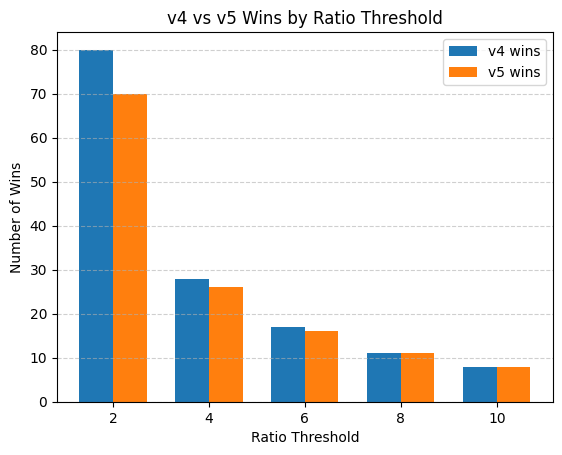

In [109]:
ratio_thresholds = [2, 4, 6, 8, 10]

group1_wins_list = []
group2_wins_list = []

den = np.minimum(df[f"{group1}_min"], df[f"{group2}_min"])
df["ratio"] = np.maximum(df[f"{group1}_min"], df[f"{group2}_min"]) / den.replace(0, np.nan)

for r in ratio_thresholds:
    filtered_rows = df[
        (df[f"{group1}_min"] > 1) &
        (df[f"{group2}_min"] > 1) &
        (df["ratio"] >= r)
    ]

    total = len(filtered_rows)

    group1_wins = (filtered_rows[f"{group1}_min"] < filtered_rows[f"{group2}_min"]).sum()
    group2_wins = total - group1_wins

    group1_wins_list.append(group1_wins)
    group2_wins_list.append(group2_wins)

# Plot
x = np.arange(len(ratio_thresholds))
width = 0.35

plt.figure()

plt.bar(x - width/2, group1_wins_list, width, label=f"{group1} wins")
plt.bar(x + width/2, group2_wins_list, width, label=f"{group2} wins")

plt.xticks(x, [f"{r}" for r in ratio_thresholds])
plt.xlabel("Ratio Threshold")
plt.ylabel("Number of Wins")
plt.title(f"{group1} vs {group2} Wins by Ratio Threshold")

plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.show()